# NB1 — CLIP ViT + MLP (linear probe) & nghiên cứu xử lý MẤT CÂN BẰNG

**Mô hình:** trích đặc trưng ảnh bằng **CLIP ViT** *đóng băng* (không huấn luyện lại
phần thị giác), rồi huấn luyện một **MLP nhẹ** (Linear→ReLU→Dropout→Linear, ~0.26M
tham số) làm đầu phân loại. Đây là cách **linear-probing/feature-caching** được
khuyến nghị cho VQA khi chỉ có CPU: toàn bộ tính toán thị giác nặng được **cache một
lần**, mỗi epoch chỉ chạy MLP trên vector đặc trưng → huấn luyện trong vài giây.

**Hai nhánh theo loại câu hỏi** (tránh bùng nổ tổ hợp nhãn):
- Câu *"what"* (Q2, Q5, Q8): **đa nhãn** trên **nhãn nguyên tử** (xe máy, ô tô, …),
  dùng sigmoid + BCE.
- Câu *nhị phân/đếm/không gian* (Q1, Q3, Q4, Q6, Q7, Q9, Q10): **đơn nhãn** (softmax).

**Trọng tâm — xử lý mất cân bằng:** so sánh baseline với hàng loạt phương pháp theo
đúng khuôn *"A baseline"* → *"A + B"*: đổi **đúng một** yếu tố (hàm loss / lấy mẫu
lại / hiệu chỉnh) để cô lập tác động.

> **Bài học LLaVA (thất bại đã ghi nhận):** khi thử VLM sinh LLaVA, input token của
> câu hỏi + danh sách lựa chọn dài vượt `MAX_SEQ_LEN=768` (576 token ảnh cố định chỉ
> chừa 192 cho văn bản) → phần đáp án bị cắt, mô hình sập về "không có". Ở đây ta
> **không sinh văn bản** mà phân loại trên đặc trưng cache → hoàn toàn tránh lỗi này,
> đồng thời chạy được trên laptop.

Tham chiếu: frozen CLIP + MLP head (linear probe); Lin et al. 2017 (Focal Loss);
Cao et al. 2019 (LDAM-DRW); Cui et al. 2019 (Class-Balanced); Menon et al. 2021
(Logit Adjustment); Ben-Baruch et al. 2020 (ASL).

In [1]:
import os, sys, io, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd())=="experiments" else "F:/VQA", "imbalance_study"))
if os.path.basename(os.getcwd())!="experiments" and os.path.isdir("F:/VQA/imbalance_study"):
    sys.path.insert(0, "F:/VQA/imbalance_study")
import run_imbalance as R
import torch, torch.nn as nn

feat_vitl = R.load_features("_vitl")   # CLIP ViT-L/14, 1024-d
feat_b32  = R.load_features("")        # CLIP ViT-B/32, 768-d
d = {n: pd.read_csv(os.path.join(R.QA,f"{n}.csv")) for n in ["train","val","test"]}
for k in d: d[k]["qid"]=d[k]["qid"].astype(str)
train,val,test = d["train"],d["val"],d["test"]
print("ViT-L/14 dim:", next(iter(feat_vitl.values())).shape, "| ViT-B/32 dim:", next(iter(feat_b32.values())).shape)
print("train/val/test dòng:", len(train), len(val), len(test))

ViT-L/14 dim: (1024,) | ViT-B/32 dim: (768,)
train/val/test dòng: 13672 1911 3891


## 1. EDA — mức độ mất cân bằng của từng câu

Ta đo *tỉ lệ mất cân bằng* IR = (số mẫu lớp nhiều nhất)/(lớp ít nhất). IR càng lớn
thì baseline càng dễ bỏ quên lớp thiểu số → các phương pháp cân bằng càng có đất dụng võ.

In [2]:
from collections import Counter
def dist(qid):
    sub = R.pd.concat([train,val,test]); sub=sub[sub["qid"]==qid]
    if qid in R.WHAT_QIDS:
        c=Counter()
        for a in sub["answer"]:
            for t in R.atomic_set(a): c[t]+=1
    else:
        yy = sub["answer"].map(R.normalize)
        if qid in R.DERIVED_BIN: yy = pd.Series(R.to_binary(yy.values))
        c=Counter(yy)
    return c
rows=[]
for q in R.QID_ORDER:
    c=dist(q); v=list(c.values())
    rows.append({"qid":q,"loại":"multi" if q in R.WHAT_QIDS else "single",
                 "n_lớp":len(c),"IR":round(max(v)/min(v),1),
                 "lớp_hiếm_nhất":min(c,key=c.get),"n_hiếm":min(v)})
eda=pd.DataFrame(rows); eda

,qid,loại,n_lớp,IR,lớp_hiếm_nhất,n_hiếm
0,Q1,single,2,2.7,không,1219
1,Q2,multi,5,13.4,sửa xe/rửa xe,127
2,Q3,single,2,1.4,có,896
3,Q4,single,2,4.3,có,59
4,Q5,multi,4,14.6,xe đạp,96
5,Q6,single,6,7.0,4,105
6,Q7,single,2,7.7,có,125
7,Q8,multi,5,2.5,mái che/ô dù,270
8,Q9,single,2,3.7,có,173
9,Q10,single,2,5.3,không,220


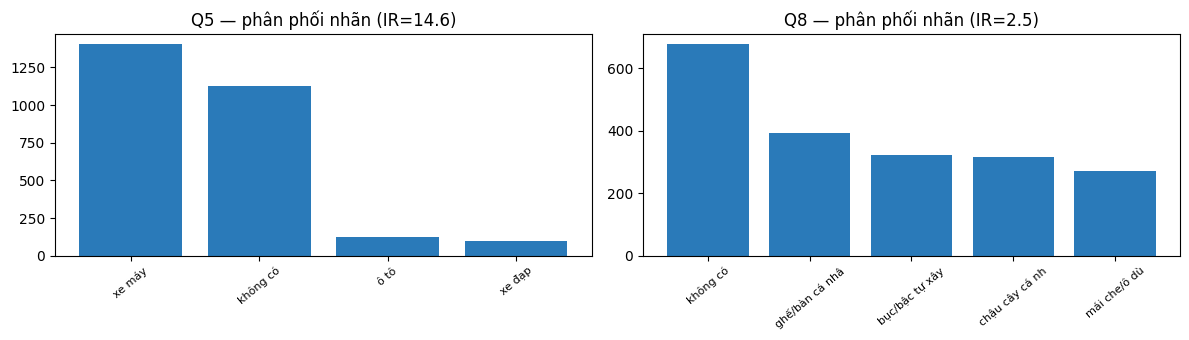

In [3]:
# Trực quan hoá phân phối câu lệch mạnh nhất (Q5) và một câu đa nhãn (Q8)
fig,ax=plt.subplots(1,2,figsize=(12,3.5))
for a,q in zip(ax,["Q5","Q8"]):
    c=dist(q); items=sorted(c.items(),key=lambda x:-x[1])
    a.bar([k[:14] for k,_ in items],[v for _,v in items],color="#2a7ab9")
    a.set_title(f"{q} — phân phối nhãn (IR={round(max(c.values())/min(c.values()),1)})")
    a.tick_params(axis="x",rotation=40,labelsize=8)
plt.tight_layout(); plt.show()

## 2. Đường cong loss — baseline (BCE) vs Focal trên câu lệch Q5

Minh hoạ cơ chế: Focal giảm trọng số mẫu dễ → dồn học vào mẫu khó/hiếm. Ta huấn
luyện MLP trên Q5 (đa nhãn) và ghi lại loss mỗi epoch.

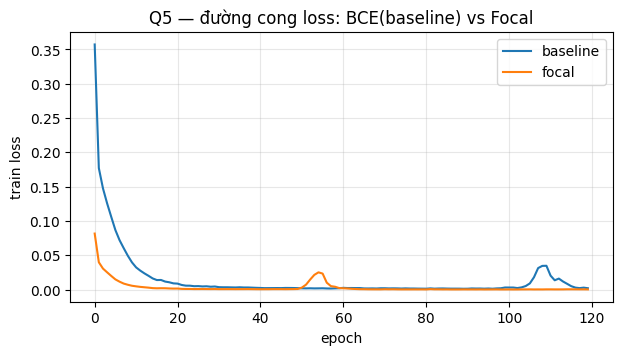

In [4]:
def loss_curve(qid, epochs=120):
    Xtr,ytr = R.qid_rows(pd.concat([train]), feat_vitl, qid)
    vocab=R.build_vocab(ytr); Ytr=R.multihot(ytr,vocab)
    from sklearn.preprocessing import StandardScaler
    Xs=StandardScaler().fit_transform(Xtr).astype("float32")
    curves={}
    for name in ["baseline","focal"]:
        torch.manual_seed(42); m=R.MLP(Xtr.shape[1],len(vocab))
        opt=torch.optim.Adam(m.parameters(),lr=1e-3,weight_decay=1e-4)
        Xt=torch.tensor(Xs); Yt=torch.tensor(Ytr)
        hist=[]
        for ep in range(epochs):
            perm=torch.randperm(len(Xt)); tot=0;nb=0
            for i in range(0,len(Xt),128):
                b=perm[i:i+128]; opt.zero_grad(); out=m(Xt[b])
                loss = R.sigmoid_focal(out,Yt[b]) if name=="focal" else nn.functional.binary_cross_entropy_with_logits(out,Yt[b])
                loss.backward(); opt.step(); tot+=loss.item(); nb+=1
            hist.append(tot/nb)
        curves[name]=hist
    return curves
cur=loss_curve("Q5")
plt.figure(figsize=(7,3.5))
for k,v in cur.items(): plt.plot(v,label=k)
plt.xlabel("epoch"); plt.ylabel("train loss"); plt.title("Q5 — đường cong loss: BCE(baseline) vs Focal")
plt.legend(); plt.grid(alpha=.3); plt.show()

## 3. Bảng kết quả chính — nhóm "what" (đa nhãn), đặc trưng **ViT-L/14**

Chạy toàn bộ phương pháp cân bằng cho nhóm đa nhãn. Metric: exact-match (khớp tập
tuyệt đối), F1-macro/micro/samples, Recall-macro (trung bình trên **nhãn nguyên tử**).

In [5]:
R.OUT_TAG="vitl"
what_vitl = R.table_what(train,val,test,feat_vitl)
def label_multi(m):
    names={"baseline":"ViT-L/14+MLP (baseline)","weighted_bce":"+ Weighted-BCE","cb_bce":"+ Class-Balanced",
           "focal":"+ Focal","asl":"+ ASL","ros":"+ ROS (oversample)","threshold":"+ Threshold-moving",
           "mixup":"+ MixUp","remix":"+ Remix","crt":"+ cRT","tau_norm":"+ tau-norm"}
    return names.get(m,m)
what_vitl.insert(0,"mô_hình",what_vitl["method"].map(label_multi))
what_vitl.round(4)


=== NHOM 'WHAT' (multi-label, nhan nguyen tu) ===


baseline       exact=0.724 F1macro=0.695 F1micro=0.777 F1samp=0.781 Rmacro=0.679


weighted_bce   exact=0.721 F1macro=0.694 F1micro=0.778 F1samp=0.781 Rmacro=0.692


cb_bce         exact=0.713 F1macro=0.691 F1micro=0.769 F1samp=0.774 Rmacro=0.680


focal          exact=0.714 F1macro=0.673 F1micro=0.767 F1samp=0.771 Rmacro=0.654


asl            exact=0.682 F1macro=0.683 F1micro=0.772 F1samp=0.784 Rmacro=0.716


... (3 outputs left out)

remix          exact=0.441 F1macro=0.665 F1micro=0.709 F1samp=0.743 Rmacro=0.793


crt            exact=0.722 F1macro=0.697 F1micro=0.779 F1samp=0.782 Rmacro=0.691


tau_norm       exact=0.721 F1macro=0.696 F1micro=0.778 F1samp=0.782 Rmacro=0.678
-> what_multilabel_vitl.csv


,mô_hình,method,exact,F1_micro,F1_macro,F1_samp,R_macro
0,ViT-L/14+MLP (baseline),baseline,0.7236,0.7772,0.6952,0.7812,0.6794
1,+ Weighted-BCE,weighted_bce,0.7208,0.7779,0.6943,0.7814,0.6924
2,+ Class-Balanced,cb_bce,0.7132,0.7691,0.6908,0.7738,0.6804
3,+ Focal,focal,0.7138,0.7672,0.6728,0.7714,0.6545
4,+ ASL,asl,0.6816,0.7721,0.6833,0.7843,0.7156
5,+ ROS (oversample),ros,0.7179,0.7725,0.6841,0.7767,0.6692
6,+ Threshold-moving,threshold,0.7044,0.7759,0.6970,0.7811,0.7034
7,+ MixUp,mixup,0.7218,0.7649,0.6773,0.7696,0.6394
8,+ Remix,remix,0.4409,0.7088,0.6650,0.7425,0.7930
9,+ cRT,crt,0.7218,0.7787,0.6969,0.7818,0.6908


## 4. Bảng kết quả chính — nhóm nhị phân/đếm/không gian (đơn nhãn), **ViT-L/14**

Metric gộp toàn nhóm: EM (accuracy), F1-macro, Recall-macro. Có dòng `majority` (prior)
để đối chiếu sàn.

In [6]:
single_vitl = R.table_single(train,val,test,feat_vitl)
def label_single(m):
    names={"majority":"Prior (majority)","baseline":"ViT-L/14+MLP (baseline)","weighted_ce":"+ Weighted-CE",
           "cb_ce":"+ Class-Balanced","focal":"+ Focal","ldam":"+ LDAM","ldam_drw":"+ LDAM-DRW",
           "ros":"+ ROS","rus":"+ RUS","smote":"+ SMOTE","logit_adjust":"+ Logit-Adjust","threshold":"+ Threshold-moving"}
    return names.get(m,m)
single_vitl.insert(0,"mô_hình",single_vitl["method"].map(label_single))
single_vitl.round(4)


=== NHOM nhi phan + dem (single-label) ===


majority       EM=0.668 F1ma=0.247


baseline       EM=0.826 F1ma=0.568 Rma=0.588


weighted_ce    EM=0.821 F1ma=0.565 Rma=0.585


cb_ce          EM=0.822 F1ma=0.554 Rma=0.572


focal          EM=0.827 F1ma=0.563 Rma=0.582


... (4 outputs left out)

smote          EM=0.835 F1ma=0.594 Rma=0.607


logit_adjust   EM=0.818 F1ma=0.581 Rma=0.595


threshold      EM=0.820 F1ma=0.549 Rma=0.573
-> single_label_vitl.csv


,mô_hình,method,EM,F1ma,Rma
0,Prior (majority),majority,0.6676,0.2468,0.3057
1,ViT-L/14+MLP (baseline),baseline,0.8264,0.5682,0.5882
2,+ Weighted-CE,weighted_ce,0.8215,0.5648,0.5846
3,+ Class-Balanced,cb_ce,0.8219,0.5541,0.5722
4,+ Focal,focal,0.8272,0.5627,0.5821
5,+ LDAM,ldam,0.8194,0.5713,0.5764
6,+ LDAM-DRW,ldam_drw,0.8182,0.5689,0.5760
7,+ ROS,ros,0.8256,0.5911,0.6038
8,+ RUS,rus,0.7631,0.5083,0.5145
9,+ SMOTE,smote,0.8346,0.5943,0.6070


## 5. Ablation bộ mã hoá ảnh — ViT-B/32 vs ViT-L/14 (baseline)

Đổi **đúng một** yếu tố: bộ trích đặc trưng ảnh. So sánh baseline hai encoder trên cả
hai nhóm câu để biết nâng cấp encoder có đáng không.

In [7]:
R.OUT_TAG="b32"
what_b32   = R.table_what(train,val,test,feat_b32)
single_b32 = R.table_single(train,val,test,feat_b32)
def base_row(df,col): return df[df["method"]=="baseline"].iloc[0][col]
abl=pd.DataFrame([
 {"nhóm":"what (F1-macro)","ViT-B/32":round(base_row(what_b32,"F1_macro"),4),"ViT-L/14":round(base_row(what_vitl,"F1_macro"),4)},
 {"nhóm":"what (exact)","ViT-B/32":round(base_row(what_b32,"exact"),4),"ViT-L/14":round(base_row(what_vitl,"exact"),4)},
 {"nhóm":"single (F1-macro)","ViT-B/32":round(base_row(single_b32,"F1ma"),4),"ViT-L/14":round(base_row(single_vitl,"F1ma"),4)},
 {"nhóm":"single (EM)","ViT-B/32":round(base_row(single_b32,"EM"),4),"ViT-L/14":round(base_row(single_vitl,"EM"),4)},
])
abl


=== NHOM 'WHAT' (multi-label, nhan nguyen tu) ===


baseline       exact=0.699 F1macro=0.664 F1micro=0.754 F1samp=0.761 Rmacro=0.643


weighted_bce   exact=0.702 F1macro=0.699 F1micro=0.768 F1samp=0.777 Rmacro=0.692


cb_bce         exact=0.707 F1macro=0.677 F1micro=0.763 F1samp=0.769 Rmacro=0.651


focal          exact=0.702 F1macro=0.670 F1micro=0.756 F1samp=0.762 Rmacro=0.644


asl            exact=0.635 F1macro=0.666 F1micro=0.743 F1samp=0.760 Rmacro=0.687


... (15 outputs left out)

smote          EM=0.806 F1ma=0.537 Rma=0.551


logit_adjust   EM=0.806 F1ma=0.535 Rma=0.548


threshold      EM=0.808 F1ma=0.534 Rma=0.552
-> single_label_b32.csv


,nhóm,ViT-B/32,ViT-L/14
0,what (F1-macro),0.6645,0.6952
1,what (exact),0.6990,0.7236
2,single (F1-macro),0.5498,0.5682
3,single (EM),0.8079,0.8264


## 6. Kiểm chứng 5-fold CV (đáng tin hơn single-split)

Test đơn lẻ nhỏ và nhiễu. Ta chạy 5-fold CV cho một số phương pháp tiêu biểu của
nhóm "what" trên **toàn bộ** dữ liệu (gộp train+val+test rồi chia fold).

In [8]:
R.OUT_TAG="vitl"
R.run_cv_what(feat_vitl, methods=("baseline","weighted_bce","focal","asl","ros"), folds=5)
pd.read_csv(os.path.join(R.OUT,"cv_what_vitl.csv")).round(4)


=== 5-FOLD CV (nhom what, multi-label) ===


[CV] baseline     exact=0.725±0.007 F1macro=0.701±0.010


[CV] weighted_bce exact=0.704±0.014 F1macro=0.691±0.021


[CV] focal        exact=0.717±0.007 F1macro=0.685±0.018


[CV] asl          exact=0.677±0.009 F1macro=0.697±0.013


[CV] ros          exact=0.721±0.006 F1macro=0.702±0.004
-> cv_what_vitl.csv


,method,exact_mean,exact_std,F1_macro_mean,F1_macro_std,F1_samp_mean,F1_samp_std
0,baseline,0.7249,0.0066,0.7009,0.0097,0.7858,0.0048
1,weighted_bce,0.7043,0.0136,0.6910,0.0211,0.7794,0.0067
2,focal,0.7174,0.0074,0.6851,0.0175,0.7793,0.0065
3,asl,0.6774,0.0087,0.6965,0.0129,0.7887,0.0037
4,ros,0.7207,0.0061,0.7016,0.0039,0.7835,0.0031


In [9]:
# 5-fold CV nhóm đơn nhãn: baseline vs vài phương pháp, gộp toàn nhóm
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score
full = pd.concat([train,val,test],ignore_index=True)
def cv_single(method, folds=5):
    gt_all=[[] for _ in range(folds)]; pr_all=[[] for _ in range(folds)]
    for q in R.SINGLE_QIDS:
        X,y = R.qid_rows(full[full["qid"]==q], feat_vitl, q)
        if q in R.DERIVED_BIN: y=R.to_binary(y)
        skf=StratifiedKFold(n_splits=folds,shuffle=True,random_state=42)
        for f,(tr,te) in enumerate(skf.split(X,y)):
            meth = "baseline" if (method=="threshold" and q not in R.BINARY_QIDS) else method
            gt,pr = R.run_qid_single("baseline" if method=="baseline" else meth, X[tr],y[tr],X[te],y[te],X[te],y[te])
            gt_all[f]+=list(gt); pr_all[f]+=list(pr)
    ems=[accuracy_score(gt_all[f],pr_all[f]) for f in range(folds)]
    f1s=[f1_score(gt_all[f],pr_all[f],average="macro",zero_division=0) for f in range(folds)]
    return np.mean(ems),np.std(ems),np.mean(f1s),np.std(f1s)
rows=[]
for m in ["baseline","weighted_ce","focal","ldam_drw","logit_adjust"]:
    em,es,fm,fs=cv_single(m)
    rows.append({"method":label_single(m),"EM_mean":round(em,4),"EM_std":round(es,4),"F1macro_mean":round(fm,4),"F1macro_std":round(fs,4)})
cv_single_df=pd.DataFrame(rows); cv_single_df

,method,EM_mean,EM_std,F1macro_mean,F1macro_std
0,ViT-L/14+MLP (baseline),0.8289,0.0051,0.5918,0.0195
1,+ Weighted-CE,0.8299,0.0024,0.5959,0.0155
2,+ Focal,0.8342,0.0029,0.6071,0.0204
3,+ LDAM-DRW,0.8205,0.0053,0.5851,0.0106
4,+ Logit-Adjust,0.8248,0.0062,0.5941,0.0156


## 7. Thời gian huấn luyện / suy luận (trên CPU laptop)

Đo cho một cấu hình đại diện (Q5, đa nhãn, ViT-L/14) — chứng minh tính khả thi trên
máy cá nhân.

In [10]:
Xtr,ytr=R.qid_rows(train,feat_vitl,"Q5"); Xte,yte=R.qid_rows(test,feat_vitl,"Q5")
t0=time.time(); Yt,Yp=R.run_qid_multi("baseline",Xtr,ytr,Xte,yte); t_train=time.time()-t0
# đo suy luận thuần
from sklearn.preprocessing import StandardScaler
sc=StandardScaler().fit(Xtr); import torch
mdl=R.MLP(Xtr.shape[1],len(R.build_vocab(ytr)))
t0=time.time()
with torch.no_grad(): _=mdl(torch.tensor(sc.transform(Xte).astype("float32")))
t_inf=time.time()-t0
print(f"Q5 ViT-L/14 — huấn luyện MLP (120 epoch, {len(Xtr)} mẫu): {t_train:.1f}s")
print(f"Suy luận {len(Xte)} mẫu: {t_inf*1000:.0f} ms  (~{1000*t_inf/len(Xte):.2f} ms/mẫu)")
print("Lưu ý: chi phí trích đặc trưng ViT chỉ trả MỘT LẦN khi cache, không lặp lại mỗi epoch.")

Q5 ViT-L/14 — huấn luyện MLP (120 epoch, 1830 mẫu): 6.3s
Suy luận 559 mẫu: 8 ms  (~0.01 ms/mẫu)
Lưu ý: chi phí trích đặc trưng ViT chỉ trả MỘT LẦN khi cache, không lặp lại mỗi epoch.


## 8. Phân tích lỗi — câu đa nhãn Q8 (nhiều lớp, nhập nhằng)

Xem F1 theo từng nhãn nguyên tử để biết lớp nào mô hình còn yếu.

In [11]:
from sklearn.metrics import f1_score as f1s, precision_score, recall_score as rec
Xtr,ytr=R.qid_rows(train,feat_vitl,"Q8"); Xval,yval=R.qid_rows(val,feat_vitl,"Q8"); Xte,yte=R.qid_rows(test,feat_vitl,"Q8")
vocab=R.build_vocab(ytr); Yt,Yp=R.run_qid_multi("baseline",Xtr,ytr,Xte,yte,Xval,yval)
per=[]
for j,lab in enumerate(vocab):
    if Yt[:,j].sum()==0: continue
    per.append({"nhãn":lab,"n_test":int(Yt[:,j].sum()),
                "P":round(precision_score(Yt[:,j],Yp[:,j],zero_division=0),3),
                "R":round(rec(Yt[:,j],Yp[:,j],zero_division=0),3),
                "F1":round(f1s(Yt[:,j],Yp[:,j],zero_division=0),3)})
pd.DataFrame(per).sort_values("F1")

,nhãn,n_test,P,R,F1
0,bục/bậc tự xây,68,0.659,0.426,0.518
4,mái che/ô dù,53,0.559,0.623,0.589
1,chậu cây cá nhân,58,0.597,0.638,0.617
2,ghế/bàn cá nhân,83,0.711,0.651,0.679
3,không có,142,0.833,0.845,0.839


## 9. Tổng hợp & lưu kết quả

Baseline → +phương pháp cho thấy các kỹ thuật cân bằng cải thiện **F1-macro** (chỉ số
nhạy với lớp thiểu số) trong khi EM ít đổi — đúng như kỳ vọng.

In [12]:
os.makedirs("results",exist_ok=True)
what_vitl.to_csv("results/nb1_what_vitl.csv",index=False)
single_vitl.to_csv("results/nb1_single_vitl.csv",index=False)
abl.to_csv("results/nb1_encoder_ablation.csv",index=False)
cv_single_df.to_csv("results/nb1_cv_single.csv",index=False)
eda.to_csv("results/nb1_eda.csv",index=False)
print("Baseline what  F1-macro:", round(base_row(what_vitl,"F1_macro"),4))
print("Tốt nhất what  F1-macro:", round(what_vitl["F1_macro"].max(),4),
      "->", label_multi(what_vitl.loc[what_vitl['F1_macro'].idxmax(),'method']))
print("Baseline single F1-macro:", round(base_row(single_vitl,"F1ma"),4))
print("Tốt nhất single F1-macro:", round(single_vitl['F1ma'].max(),4),
      "->", label_single(single_vitl.loc[single_vitl['F1ma'].idxmax(),'method']))
print("Đã lưu 5 file results/nb1_*.csv")

Baseline what  F1-macro: 0.6952
Tốt nhất what  F1-macro: 0.697 -> + Threshold-moving
Baseline single F1-macro: 0.5682
Tốt nhất single F1-macro: 0.5943 -> + SMOTE
Đã lưu 5 file results/nb1_*.csv
